# 08 — Error analysis

**Objective.** Inspect where the deployed classifier and the retrieval system fail.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (9, 4)
from ml.config import PROCESSED_DATASET, ARTIFACTS_DIR, METADATA_DIR, RAW_DIR
df = pd.read_csv(PROCESSED_DATASET)
print(f'{len(df):,} processed fact-checks')

4,137 processed fact-checks


In [2]:
pred = pd.read_csv(ARTIFACTS_DIR / 'test_predictions.csv')
pred['correct'] = pred.label == pred.predicted
print(f"test accuracy {pred.correct.mean():.3f}"); pd.crosstab(pred.label, pred.predicted, normalize='index').round(2)

test accuracy 0.555


predicted,FALSE,MISLEADING,OUTDATED
label,,,
FALSE,0.62,0.26,0.12
MISLEADING,0.30,0.59,0.11
OUTDATED,0.34,0.30,0.36


## Most confident mistakes

In [3]:
pred[~pred.correct].sort_values('confidence', ascending=False).head(12)[['label','predicted','confidence','language','claim_text']]

,label,predicted,confidence,language,claim_text
142,OUTDATED,FALSE,0.9758,hi,बिहार चुनाव: RJD से टिकट नहीं मिलने पर रोने लग...
287,FALSE,MISLEADING,0.9545,en,The video shows a Maulana being beaten in Paki...
378,MISLEADING,FALSE,0.9513,kn,ದಿವಂಗತ ಕ್ಯಾಪ್ಟನ್ ಅಂಶುಮಾನ್ ಸಿಂಗ್ ಅವರ ಪತ್ನಿ ಸ್ಮೃ...
310,OUTDATED,MISLEADING,0.9422,en,A video showing two Muslim men setting fire to...
228,MISLEADING,FALSE,0.9360,en,UN modified resolution on Pahalgam? Kiran Bedi...
405,OUTDATED,FALSE,0.9274,kn,ಹರಿಯಾಣದ ಮಾಜಿ ಮುಖ್ಯಮಂತ್ರಿ ಮನೋಹರ್ ಲಾಲ್ ಖಟ್ಟರ್ ಅವ...
129,MISLEADING,FALSE,0.9258,kn,ಇದು ಉತ್ತರ ಪ್ರದೇಶ ಪೊಲೀಸರು ಹುಡುಗಿಯೊಬ್ಬಳ ಜೊತೆ ಅನು...
115,FALSE,MISLEADING,0.9241,en,The video shows a money-laden truck meeting wi...
381,MISLEADING,FALSE,0.9214,en,Did Yogi Adityanath not greet PM Modi at CMs' ...
500,FALSE,OUTDATED,0.9193,kn,ಅಮೃತಸರದ ಅಪಘಾತದ ವಿಡಿಯೋವನ್ನು ಯುಪಿ ಸರ್ಕಾರ ರೈತರ ಪ್...


## Errors by language and input type

In [4]:
pred.groupby(['language','claim_source'])['correct'].agg(['mean','size']).round(3)

mean  size
language claim_source             
en       claim_field   0.601   193
         title         0.491   106
hi       title         0.546   119
kn       claim_field   0.481    54
         title         0.617    47

## Accuracy against confidence

In [5]:
pred['bucket'] = pd.cut(pred.confidence, [0, .4, .5, .6, .7, .8, 1])
pred.groupby('bucket', observed=True)['correct'].agg(['mean','size']).round(3)

,mean,size
bucket,,
"(0.0, 0.4]",0.444,9
"(0.4, 0.5]",0.424,66
"(0.5, 0.6]",0.443,106
"(0.6, 0.7]",0.469,113
"(0.7, 0.8]",0.593,86
"(0.8, 1.0]",0.755,139


## Retrieval evaluation

In [6]:
rev = json.loads((ARTIFACTS_DIR / 'retrieval_eval.json').read_text())
pd.DataFrame({k: {m: rev[k][m] for m in ('recall@1','recall@5','recall@10','mrr')} for k in ('hybrid','tfidf_char')}).T

,recall@1,recall@5,recall@10,mrr
hybrid,0.8447,0.9333,0.9487,0.8826
tfidf_char,0.8193,0.9213,0.9433,0.8638


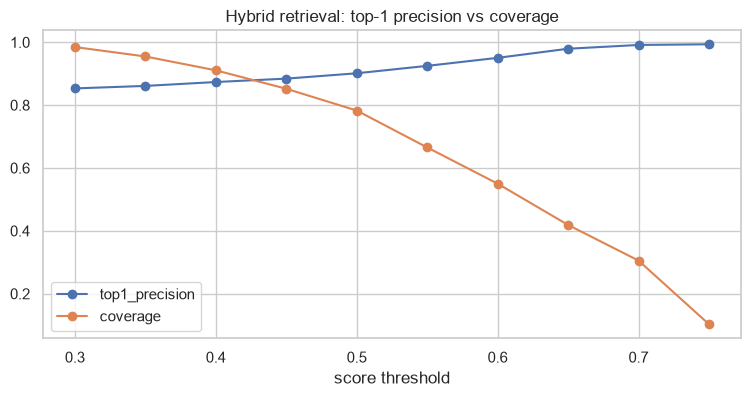

,top1_precision,coverage
0.3,0.8531,0.9847
0.35,0.8610,0.9547
0.4,0.8734,0.9107
0.45,0.8842,0.8520
0.5,0.9012,0.7827
0.55,0.9248,0.6653
0.6,0.9503,0.5500
0.65,0.9793,0.4187
0.7,0.9913,0.3053
0.8,0.9935,0.1027


In [7]:
pt = pd.DataFrame(rev['hybrid']['precision_at_threshold']).T
ax = pt.plot(marker='o'); ax.set_xlabel('score threshold'); ax.set_title('Hybrid retrieval: top-1 precision vs coverage'); plt.show(); pt

## Observations
* The largest confusion is FALSE ↔ MISLEADING (26–30% of each class), and a third of OUTDATED claims are predicted FALSE: an old video shared out of context fits several labels, and the rule-based labels add noise.
* Confidence is informative: accuracy is ~76% above 0.8 confidence versus ~44% below 0.6.
* Retrieval at score ≥ 0.60 is right ~95% of the time when the claim is in the dataset; for claims that are *not* in the dataset, false strong matches remain possible, which is why the UI asks users to confirm it is the same claim.

**Conclusion.** The biggest gains would come from (1) human-verified verdict labels, (2) more Hindi claim texts, (3) Indic-specific embeddings.